In [185]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

**1 Problem Framing (10)**

**• What type of ML problem is this?**

This is a binary classification problem. The data is supervised as it is labeled.

**• What would the prediction target be?**

We need to predict whether the borrower will default within a specific time frame.

**• What type of data would be required?**

The data would require borrower information such as age, employment status, address, income, credit utilization, credit history, and social security number, etc...

**• What evaluation metrics would be appropriate?**

Financial information such as income, credit utilization would be important. Additionally, borrower information such as age, employment status, address, and credit history would also is a factor that need to be considered.

**• What risks or challenges might arise?**

- Class imbalance, since default events are often significantly less than non-default cases.
- Data quality issue as there may not be enough information for some borrower.


**Inspect and handle missing values**

In [186]:
df = pd.read_csv("sample_data/csdata.csv", index_col=0)
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [187]:
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149998,0,0.246044,58,0,3870.000000,5400.0,18,0,1,0,0.0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


As the data is skewed, so I use median to replace data

**Examine class balance**

In [188]:
df['SeriousDlqin2yrs'].value_counts()

,count
SeriousDlqin2yrs,
0,139974
1,10026


In [189]:
df['SeriousDlqin2yrs'].value_counts(normalize=True)

,proportion
SeriousDlqin2yrs,
0,0.93316
1,0.06684


This dataset is not balanced. The percentage of default is about 6.7% and of not default is about 93.3%.

**Split into train / validation / test sets**

In [190]:
from sklearn.model_selection import train_test_split

In [191]:
X = df.drop('SeriousDlqin2yrs', axis = 1)
y = df['SeriousDlqin2yrs']

In [192]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y)

In [193]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42)

In [194]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (105000, 10)
Validation: (22500, 10)
Test: (22500, 10)


**Reusable Pipeline Construction**

In [195]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [196]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))])

In [197]:
def check_distribution_shift(X_train, X_new, threshold=0.2):
  train_mean = X_train.mean()
  new_mean = X_new.mean()
  train_std = X_train.std()
  mean_diff = abs(train_mean - new_mean) / (train_std)
  if mean_diff > threshold:
    return False
  return True

**Briefly explain why distribution checking is important in finance.**

Because financial data can change over time due to economic conditions, market cycles, or borrower behavior, if the distribution of new data differs significantly from the training data, model predictions may become unreliable. Therefore, it is important to check the distribution of the data.

**3 Logistic Regression and Convergence (25)**

In [214]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

**Train a logistic regression model**

**Record training loss per iteration (using callback or iterative fitting)**

In [199]:
loss_history = []
model = LogisticRegression(
    max_iter=1,
    warm_start=True,
    solver='lbfgs')
for i in range(50):
    model.fit(X_train, y_train)
    y_prob = model.predict_proba(X_train)
    loss = log_loss(y_train, y_prob)
    loss_history.append(loss)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

**Plot Loss vs Iteration**

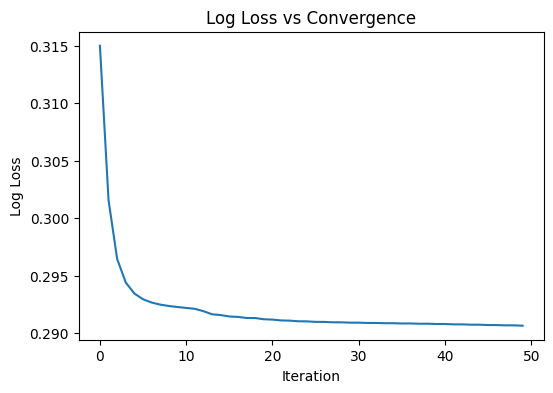

In [200]:
plt.figure(figsize=(6,4))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Convergence")
plt.show()

**Report validation Accuracy and AUC**

In [201]:
from sklearn.metrics import accuracy_score, roc_auc_score

In [202]:
y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:,1]
accuracy = accuracy_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)
print("Validation Accuracy:", accuracy)
print("Validation AUC:", auc)

Validation Accuracy: 0.9331555555555555
Validation AUC: 0.5790493306982485


**Briefly comment on:**

**• Convergence behavior**

The training loss decreases quickly during the first 10 iterations, then stablizes after 20 interations.


• Stability of training

The loss curve is more flat after 20 interations, which shows that the model started to reach stable solution after 20 interations.

**4 Loss Function and Hyperparameter Analysis (30)**

# ***Log-loss***

In [203]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_val)
y_prob_log = log_model.predict_proba(X_val)[:,1]
acc_log = accuracy_score(y_val, y_pred_log)
auc_log = roc_auc_score(y_val, y_prob_log)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [204]:
print("Logistic Regression")
print("Validation Accuracy:", acc_log)
print("Validation AUC:", auc_log)

Logistic Regression
Validation Accuracy: 0.9336444444444445
Validation AUC: 0.699156618104563


# ***Hinge loss***

In [205]:
from sklearn.linear_model import SGDClassifier

In [206]:
hinge_model = SGDClassifier(loss="hinge", max_iter=1000)
hinge_model.fit(X_train, y_train)
y_pred_hinge = hinge_model.predict(X_val)
scores = hinge_model.decision_function(X_val)
acc_hinge = accuracy_score(y_val, y_pred_hinge)
auc_hinge = roc_auc_score(y_val, scores)

In [207]:
print("Hinge Loss Model")
print("Validation Accuracy:", acc_hinge)
print("Validation AUC:", auc_hinge)

Hinge Loss Model
Validation Accuracy: 0.9225333333333333
Validation AUC: 0.5813807968235084


**Compare validation performance and discuss differences.**

Logistic regression achieved slightly better accuracy and AUC because log-loss optimizes probability estimation.

**Learning Rate Study**

In [208]:
learning_rates = [0.0001, 0.01, 0.1]
results = {}
loss_history = {}

for lr in learning_rates:
    model = SGDClassifier(
        loss="log_loss",
        learning_rate="constant",
        eta0=lr,
        max_iter=1,
        warm_start=True)

    current_lr_losses = []
    for i in range(50):
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_train)
        loss = log_loss(y_train, prob)
        current_lr_losses.append(loss)
        if i == 49:
            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:,1]
            acc = accuracy_score(y_val, y_pred)
            auc = roc_auc_score(y_val, y_prob)
            results[lr] = (acc, auc)
    loss_history[lr] = current_lr_losses

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic

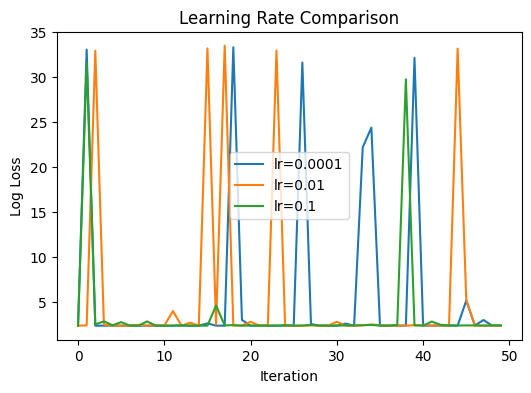

In [209]:
plt.figure(figsize=(6,4))
for lr in learning_rates:
    plt.plot(loss_history[lr], label=f"lr={lr}")
plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()

In [210]:
for lr,(acc, auc) in results.items():
    print(f"Learning Rate {lr}")
    print("Validation Accuracy:", acc)
    print("Validation AUC:", auc)
    print()

Learning Rate 0.0001
Validation Accuracy: 0.9328444444444445
Validation AUC: 0.4957090990989165

Learning Rate 0.01
Validation Accuracy: 0.9332
Validation AUC: 0.5040124315725792

Learning Rate 0.1
Validation Accuracy: 0.9323111111111111
Validation AUC: 0.49971339208988136



Compare:

*• Convergence speed:* higher learning rates converge quicker

*• Stability:* smaller learning rates tend to have better stability

*• Final validation performance:* the smallest learning rate (0.0001) produced the best AUC, while accuracy looks similar for different learning rates.

**Regularization Study**
Experiment with at least three regularization strengths.
Discuss:
• Overfitting vs underfitting
• Validation performance changes
Grid Search
Perform grid search over:
• Learning rate
• Regularization strength
Report:
• Best parameter combination
• Best validation AUC

In [211]:
alphas = [0.0001, 0.01, 1.0]
for alpha in alphas:
    model = SGDClassifier(
        loss="log_loss",
        alpha=alpha,
        max_iter=1000)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:,1]
    acc = accuracy_score(y_val, pred)
    auc = roc_auc_score(y_val, prob)
    print("Alpha:", alpha)
    print("Validation Accuracy:", acc)
    print("Validation AUC:", auc)
    print()

Alpha: 0.0001
Validation Accuracy: 0.9305777777777777
Validation AUC: 0.5146885564322283

Alpha: 0.01
Validation Accuracy: 0.9276888888888889
Validation AUC: 0.5925870536890512

Alpha: 1.0
Validation Accuracy: 0.9332
Validation AUC: 0.627541850043372



Discuss:

• Overfitting vs underfitting

The smallest alpha (0.001) performs badly with accuracy = 0.08, which demonstrates the model is overfitting.


• Validation performance changes

As alpha = 1.0, AUC is the highest. This means as regularization increases, AUC increases.

**Grid Search**

In [212]:
learning_rates = [0.0001, 0.01, 0.1]
alphas = [0.0001, 0.01, 1.0]
best_auc = 0
best_params = None
for lr in learning_rates:
    for alpha in alphas:
        model = SGDClassifier(
            loss="log_loss",
            learning_rate="constant",
            eta0=lr,
            alpha=alpha,
            max_iter=1000)
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, prob)
        if auc > best_auc:
            best_auc = auc
            best_params = (lr, alpha)

print("Final parameters:", best_params)
print("Final validation AUC:", best_auc)

Final parameters: (0.0001, 0.0001)
Final validation AUC: 0.5420786203451112


**5 Final Model Recommendation (10)**

In [213]:
final_model = SGDClassifier(
    loss="log_loss",
    learning_rate="constant",
    eta0=best_params[0],
    alpha=best_params[1],
    max_iter=1000
)
final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)
final_auc = roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1])
print(f"Final Test AUC: {final_auc:.4f}")
print(f"Final Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

Final Test AUC: 0.4985
Final Test Accuracy: 0.9330


• State final hyperparameters chosen

- Learning rate: 0.0001
- Regularization: 0.0001
- Loss function: Log-loss


***Justify clearly why this model should be deployed***

Log-loss is recommended because it achieved the highest AUC and accuracy.